In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("covid_19_data.csv")

print(df.head())

   SNo ObservationDate Province/State  Country/Region      Last Update  \
0    1      01/22/2020          Anhui  Mainland China  1/22/2020 17:00   
1    2      01/22/2020        Beijing  Mainland China  1/22/2020 17:00   
2    3      01/22/2020      Chongqing  Mainland China  1/22/2020 17:00   
3    4      01/22/2020         Fujian  Mainland China  1/22/2020 17:00   
4    5      01/22/2020          Gansu  Mainland China  1/22/2020 17:00   

   Confirmed  Deaths  Recovered  
0        1.0     0.0        0.0  
1       14.0     0.0        0.0  
2        6.0     0.0        0.0  
3        1.0     0.0        0.0  
4        0.0     0.0        0.0  


In [3]:
print(df.isna().sum())

colFill = ["Confirmed", "Deaths", "Recovered"]

df[colFill] = df[colFill].fillna(0)

df["ObservationDate"] = pd.to_datetime(
    df["ObservationDate"]
)

df["Active"] = (
    df["Confirmed"] - df["Deaths"] - df["Recovered"]
)

df["Death_Percentage"] = np.where(
    df["Confirmed"] > 0,
    (df["Deaths"] / df["Confirmed"]) * 100,
    0
)

df["Result"] = np.where(
    df["Confirmed"] > 0,
    "Cases Found",
    "No Cases"
)

grading = [
    df["Deaths"] >= 100,
    df["Deaths"] >= 50,
    df["Deaths"] >= 10,
    df["Deaths"] > 0
]

df["Death_Level"] = np.select(
    grading,
    ["Very High", "High", "Medium", "Low"],
    default="No Deaths"
)

SNo                    0
ObservationDate        0
Province/State     78103
Country/Region         0
Last Update            0
Confirmed              0
Deaths                 0
Recovered              0
dtype: int64


In [4]:
res = df.groupby("Country/Region").agg(
    totalConfirmed=("Confirmed", "sum"),
    totalDeaths=("Deaths", "sum"),
    totalRecovered=("Recovered", "sum"),
    totalActive=("Active", "sum")
).round(1)

res = res.sort_values(
    by="totalConfirmed",
    ascending=False
).head(10)

print(res)

                totalConfirmed  totalDeaths  totalRecovered   totalActive
Country/Region                                                           
US                6.049146e+09  123303762.0    5.033710e+08  5.422471e+09
India             3.226768e+09   44424723.0    2.900590e+09  2.817535e+08
Brazil            2.653588e+09   72624610.0    2.313677e+09  2.672859e+08
Russia            9.305488e+08   18363719.0    7.907057e+08  1.214794e+08
France            8.551890e+08   22720818.0    6.940743e+07  7.630607e+08
UK                7.837944e+08   29171984.0    2.327572e+06  7.522948e+08
Spain             6.491118e+08   19065104.0    6.119362e+07  5.688530e+08
Italy             6.366943e+08   26000702.0    4.877998e+08  1.228938e+08
Turkey            6.189410e+08    6841158.0    5.641706e+08  4.792924e+07
Germany           5.241668e+08   13364216.0    4.533833e+08  5.741936e+07


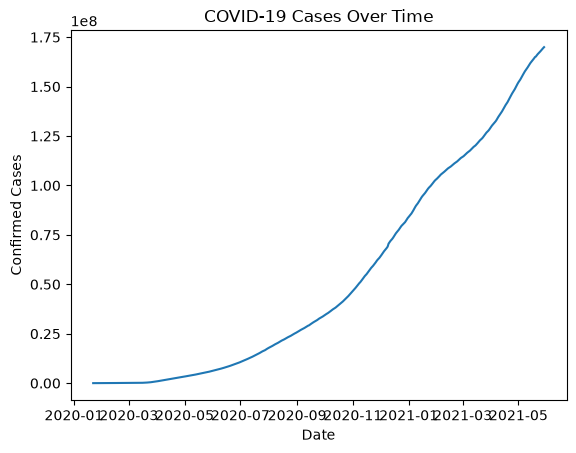

In [5]:
daily = df.groupby("ObservationDate").agg(
    Confirmed=("Confirmed", "sum")
).reset_index()

plt.plot(daily["ObservationDate"], daily["Confirmed"])

plt.xlabel("Date")
plt.ylabel("Confirmed Cases")
plt.title("COVID-19 Cases Over Time")

plt.show()

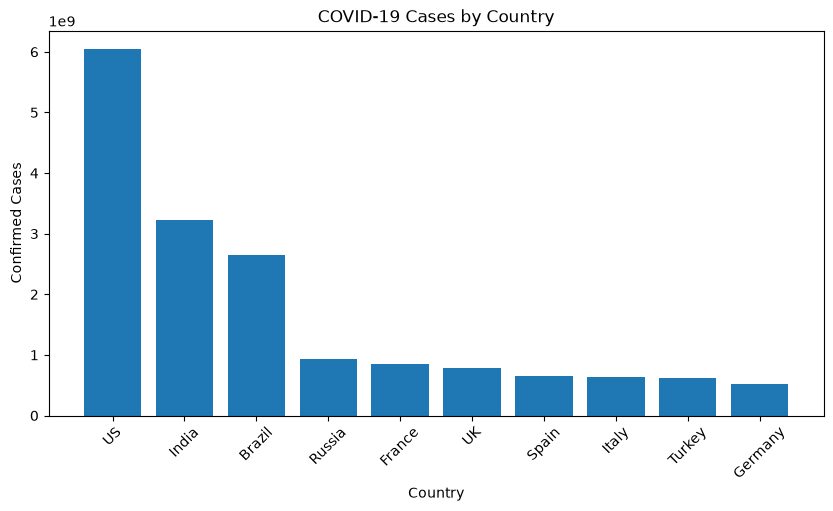

In [6]:
plt.figure(figsize=(10, 5))

plt.bar(res.index, res["totalConfirmed"])

plt.xlabel("Country")
plt.ylabel("Confirmed Cases")
plt.title("COVID-19 Cases by Country")

plt.xticks(rotation=45)
plt.show()

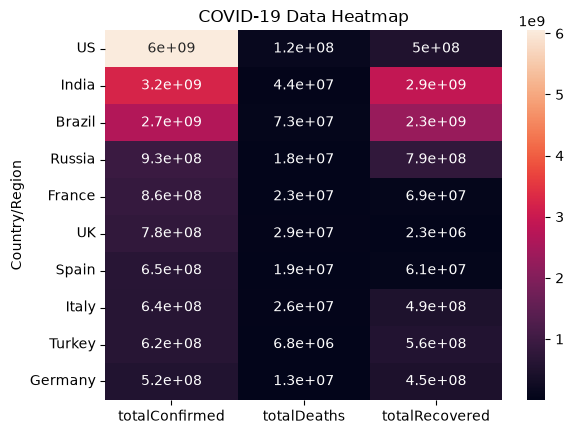

In [7]:
sns.heatmap(
    res[["totalConfirmed", "totalDeaths", "totalRecovered"]],
    annot=True
)

plt.title("COVID-19 Data Heatmap")
plt.show()